In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
from pathlib import Path
from shapely.geometry import Point
import geopandas as gpd
import sys

# Get project root and add to path
project_root = Path().resolve().parents[0] if Path().resolve().name == 'notebooks' else Path().resolve()
if project_root.name != 'nn-mar':
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from utils import PROJECT_ROOT, DATA_RAW, DATA_INTERIM

# Import project modules
preprocessing_path = PROJECT_ROOT / "src" / "preprocessing"
sys.path.append(str(preprocessing_path))

from makeTrainingFeatures import *



In [ ]:
data_path = DATA_RAW / "labels"
sed_labels_file = "sedrate_continentalshelves.csv"

df = pd.read_csv(Path(data_path / sed_labels_file))


/tmp/ipykernel_2261238/2356323753.py:6: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


,Latitude,Longitude,MAR(g/cm**2/ka)
count,10836.000000,10836.000000,10836.000000
mean,25.291575,95.849764,218.470338
std,18.950500,61.373172,304.851022
min,-72.875000,-179.458333,0.000000
25%,10.892552,102.664051,10.000000
50%,27.552345,121.754941,140.400000
75%,30.289815,123.752201,210.600000
max,81.857694,179.458333,5070.000000


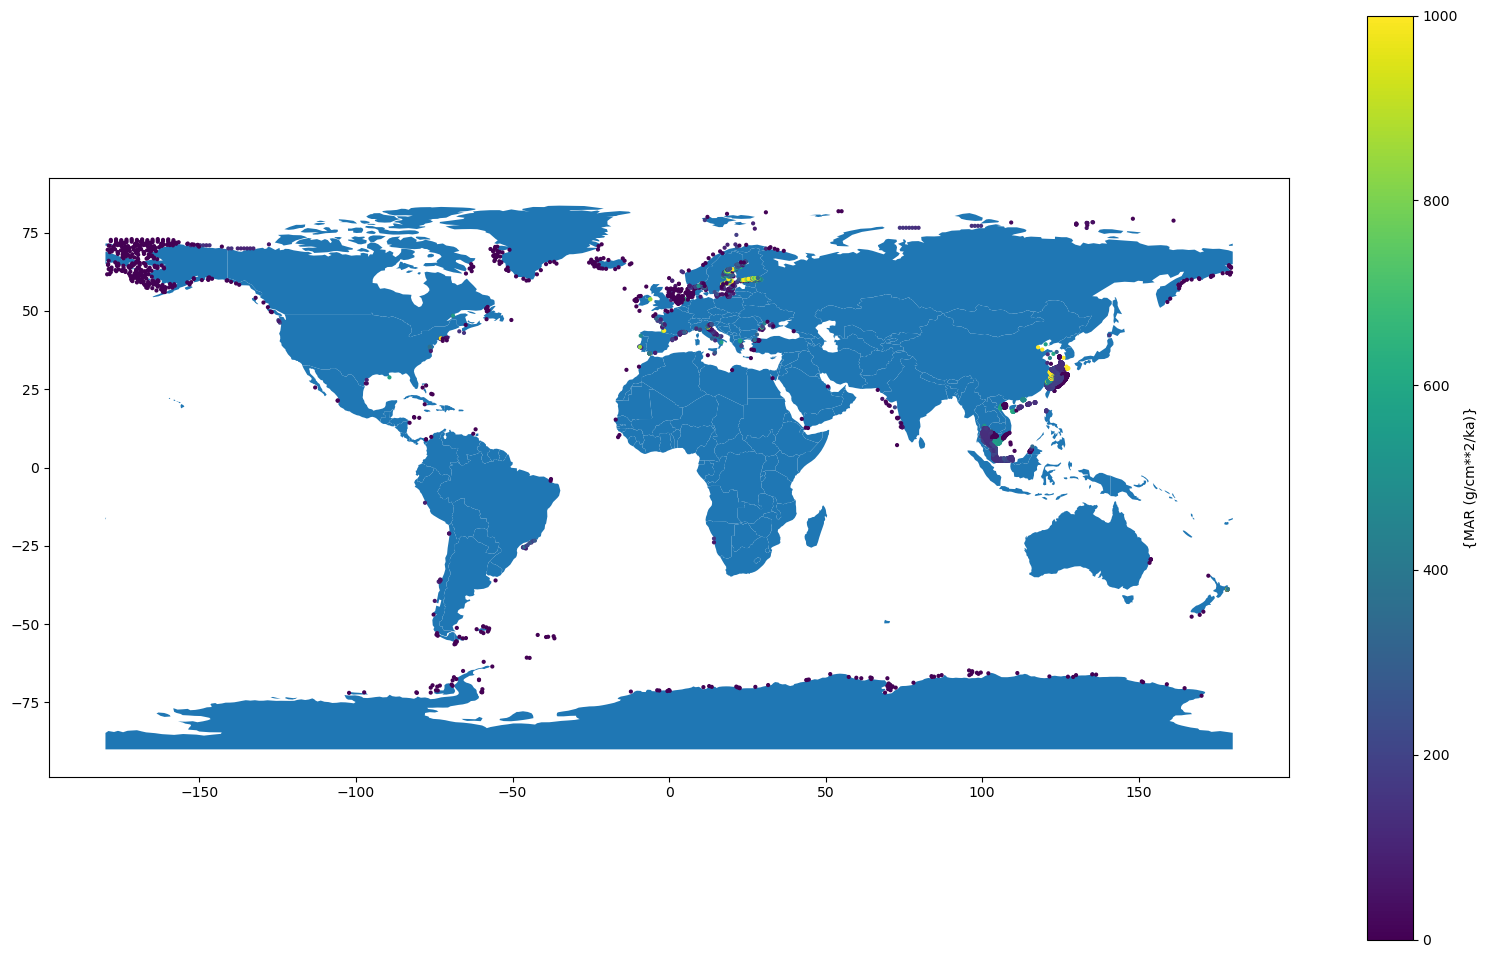

In [21]:

df = df[["Latitude","Longitude","MAR(g/cm**2/ka)"]]
df = df[df["Longitude"]>-180]
df = df.dropna(how="any")
#df = df[df["Sedimentation rate [cm/ka]"]<5000]

world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
geometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]
gdf = GeoDataFrame(df, geometry=geometry)  
gdf.plot(ax = world.plot(figsize = (20, 12)), column = df["MAR(g/cm**2/ka)"], vmin = 0, vmax = 1000,legend = True, legend_kwds={"label":"{MAR (g/cm**2/ka)}"}, markersize = 4);

df.describe()

In [4]:
df


,Latitude,Longitude,MAR(g/cm**2/ka)
0,-38.985700,178.167700,0.00000
1,-38.982300,178.179000,2316.08000
2,-38.982100,178.179600,1493.96000
3,-38.982000,178.179500,0.00000
4,-38.976300,178.167900,2245.36000
...,...,...,...
10836,-71.875000,-76.125000,0.00001
10837,-71.875000,68.958333,0.00001
10838,-71.958333,-102.208333,0.00001
10839,-71.958333,-80.541667,0.00001


In [ ]:
restrepo_features_path = DATA_RAW / "features" / "FeaturesPhrampusLee_TOCSedRate_updated"
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)



510

In [6]:
df

,Latitude,Longitude,MAR(g/cm**2/ka)
0,-38.985700,178.167700,0.00000
1,-38.982300,178.179000,2316.08000
2,-38.982100,178.179600,1493.96000
3,-38.982000,178.179500,0.00000
4,-38.976300,178.167900,2245.36000
...,...,...,...
10836,-71.875000,-76.125000,0.00001
10837,-71.875000,68.958333,0.00001
10838,-71.958333,-102.208333,0.00001
10839,-71.958333,-80.541667,0.00001


In [ ]:
restrepo_features_path = DATA_RAW / "features" / "FeaturesPhrampusLee_TOCSedRate_updated"
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)



510

In [ ]:
feature_selection = pd.read_csv(DATA_INTERIM / "selectedFeatureLists" / "selectedfeatures_v_men.txt").values

selection_filter = np.zeros(len(restrepo_files), dtype=bool)
for idx, feature_name in enumerate(filenames):
    if feature_name in feature_selection: # drop '.nc' from feature names #drop .grd
        selection_filter[idx] = True

In [9]:
filenames

[]

In [10]:
feature_selection = pd.read_csv(Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/selectedFeatureLists/selectedfeatures_v_men.txt")).values

selection_filter = np.zeros(len(restrepo_files), dtype=bool)
for idx, feature_name in enumerate(filenames):
    if feature_name in feature_selection: # drop '.nc' from feature names #drop .grd
        selection_filter[idx] = True

In [11]:
selected_files = []
for file in restrepo_files:
    if file in feature_selection:
        selected_files.append(file)

print(selected_files)

['DERIVATIVE_lithology_grain_size_Everardo_global_8.nc', 'EOT20_tidal_ratio_5arcmin_interp_land.nc', 'EOT20_u3_5arcmin_interp_land.nc', 'EOT20_umax_5arcmin_interp_land.nc', 'EOT20_urms_5arcmin_interp_land.nc', 'GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc', 'GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc', 'GL_DIST_TO_COAST_KM_ETOPO.5m.grd', 'GL_DIST_TO_COAST_KM_ETOPO.r50km.men.5m.grd', 'GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd', 'GL_ELEVATION_M_ASL_ETOPO2v2.r50km.men.5m.grd', 'GL_HEATFLUX_MWM2_Becker.5m.nc', 'GL_HEATFLUX_MWM2_Becker_r50km_men.nc', 'GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.5m.grd', 'GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.r50km.men.5m.grd', 'GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.5m.grd', 'GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.r50km.men.5m.grd', 'GL_RIVERMOUTH_HCO3_TGCYR-1_ORNL.5m.grd', 'GL_RIVERMOUTH_HCO3_TGCYR-1_ORNL.r50km.men.5m.grd', 'GL_RIVERMOUTH_POC_TGCYR-1_ORNL.5m.grd', 'GL_RIVERMOUTH_POC_TGCYR-1_ORNL.r50km.men.5m.grd

In [12]:
len(feature_selection)

110

In [13]:
restrepo_files = selected_files

In [14]:
# Convert feature_selection to a flat list of strings (in case it's not already)
feature_selection_list = [str(item).strip() for sublist in feature_selection for item in (sublist if isinstance(sublist, (list, np.ndarray)) else [sublist])]

# Find which items in feature_selection are not in restrepo_files
missing_in_restrepo = [f for f in feature_selection_list if f not in restrepo_files]

print("Files in feature_selection but not in restrepo_files:")
print(missing_in_restrepo)

Files in feature_selection but not in restrepo_files:
[]


In [15]:
print(len(restrepo_files))
restrepo_files

110


['DERIVATIVE_lithology_grain_size_Everardo_global_8.nc',
 'EOT20_tidal_ratio_5arcmin_interp_land.nc',
 'EOT20_u3_5arcmin_interp_land.nc',
 'EOT20_umax_5arcmin_interp_land.nc',
 'EOT20_urms_5arcmin_interp_land.nc',
 'GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc',
 'GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc',
 'GL_DIST_TO_COAST_KM_ETOPO.5m.grd',
 'GL_DIST_TO_COAST_KM_ETOPO.r50km.men.5m.grd',
 'GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd',
 'GL_ELEVATION_M_ASL_ETOPO2v2.r50km.men.5m.grd',
 'GL_HEATFLUX_MWM2_Becker.5m.nc',
 'GL_HEATFLUX_MWM2_Becker_r50km_men.nc',
 'GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.r50km.men.5m.grd',
 'GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.r50km.men.5m.grd',
 'GL_RIVERMOUTH_HCO3_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_HCO3_TGCYR-1_ORNL.r50km.men.5m.grd',
 'GL_RIVERMOUTH_POC_TGCYR-1_ORNL.5m.grd',
 'GL_RIVERMOUTH_POC_TGCYR-1_O

In [ ]:
rootgrp = xr.open_dataset(Path(restrepo_features_path / restrepo_files[0]), format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']
lat_labels = []
lon_labels = []

/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'cfgrib' loading failed:
Cannot find the ecCodes library
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/xarray/backends/plugins.py:110: RuntimeWarning: Engine 'gmt' loading failed:
Error loading GMT shared library at 'libgmt.so'.
libgmt.so: cannot open shared object file: No such file or directory
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [17]:
latitudes = np.array(df["Latitude"])
longitudes = np.array(df["Longitude"])
save_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_CS_men")
np.save(Path(save_path / "numpy_lat"),latitudes)
np.save(Path(save_path / "numpy_lon"),longitudes)

In [18]:
restrepo_features = np.empty([len(df),len(restrepo_files[0:len(restrepo_files)])])
restrepo_features[:] = np.nan
restrepo_X_mean = np.empty(0)
restrepo_X_std = np.empty(0)
# Create latitude array from -90 to 90 with 5 arc minute spacing
# 5 arc minutes = 5/60 = 0.0833333 degrees
# Number of points = (90 - (-90)) / (5/60) = 2160
latitudes = np.linspace(-90, 90, 2160)
longitudes = np.linspace(-180, 180, 4320)
file_idx = -1
corrupted_files = 0
lat_idx = []
lon_idx = []
for data_idx in range(0,len(df)):
    lat_idx.append(find_nearest(df.iloc[data_idx,0], latitudes))
    lon_idx.append(find_nearest(df.iloc[data_idx,1], longitudes))

for file in restrepo_files[0:len(restrepo_files)]:
    file_idx += 1
    try: 
        rootgrp = xr.open_dataset(Path(restrepo_features_path / file), format = 'NETCDF4')
    except:
        restrepo_X_mean = np.append(restrepo_X_mean,np.nan)
        restrepo_X_std = np.append(restrepo_X_std,np.nan)
        corrupted_files = corrupted_files + 1
        continue


    dataset = rootgrp.variables['data']
    
    restrepo_X_mean = np.append(restrepo_X_mean,np.nanmean(dataset))
    restrepo_X_std = np.append(restrepo_X_std,np.nanstd(dataset))
    # find the index of the file that is porosity
    if file == "SF_POROSITY_FRC.5m_with_coords_flip.nc":
        porosity_fileidx = file_idx

    #remove labels if they are above 5m to the water level
    if file == "GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd":
        for data_idx in range(0,len(df)):
    
            if dataset[lat_idx[data_idx], lon_idx[data_idx]] > 5: #elevation is negative, hence greater than 5 is above water level
                restrepo_features[data_idx, file_idx] = np.nan
            else:
                restrepo_features[data_idx, file_idx] = dataset[lat_idx[data_idx], lon_idx[data_idx]]


        print("file " + str(file_idx) + " :" + str(file)+  " done!")


    else:
        for data_idx in range(0,len(df)):
            restrepo_features[data_idx, file_idx] = dataset[lat_idx[data_idx], lon_idx[data_idx]]


        print("file " + str(file_idx) + " :" + str(file)+  " done!")


print("corrupted files: " + str(corrupted_files))

file 0 :DERIVATIVE_lithology_grain_size_Everardo_global_8.nc done!
file 1 :EOT20_tidal_ratio_5arcmin_interp_land.nc done!
file 2 :EOT20_u3_5arcmin_interp_land.nc done!
file 3 :EOT20_umax_5arcmin_interp_land.nc done!
file 4 :EOT20_urms_5arcmin_interp_land.nc done!
file 5 :GL_COMPACT_ALL_CLY_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc done!
file 6 :GL_COMPACT_ALL_SND_ISOPACH_SED_THICK_M_GLOBSED_1_8_Straume.1d_5_arc_min_interpolated.nc done!
file 7 :GL_DIST_TO_COAST_KM_ETOPO.5m.grd done!
file 8 :GL_DIST_TO_COAST_KM_ETOPO.r50km.men.5m.grd done!
file 9 :GL_ELEVATION_M_ASL_ETOPO2v2.5m.grd done!
file 10 :GL_ELEVATION_M_ASL_ETOPO2v2.r50km.men.5m.grd done!
file 11 :GL_HEATFLUX_MWM2_Becker.5m.nc done!
file 12 :GL_HEATFLUX_MWM2_Becker_r50km_men.nc done!
file 13 :GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.5m.grd done!
file 14 :GL_RIVERMOUTH_CO2_TGCYR-1_ORNL.r50km.men.5m.grd done!
file 15 :GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.5m.grd done!
file 16 :GL_RIVERMOUTH_DOC_TGCYR-1_ORNL.r50km.men.5m.

In [19]:
print("corrupted files: " + str(corrupted_files))

features = np.concatenate([restrepo_features], axis = 1)
X_mean = np.concatenate([restrepo_X_mean])
X_std = np.concatenate([restrepo_X_std])
features.shape


save_path = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/inputfeatures/SedTOCFeaturesnoNAN_MAR_CS_men")
np.save(Path(save_path / "numpy_features"), restrepo_features)
np.save(Path(save_path / "numpy_labels"), df["MAR(g/cm**2/ka)"].values)
np.save(Path(save_path / "features_mean"),restrepo_X_mean)
np.save(Path(save_path / "features_std"),restrepo_X_std)


corrupted files: 0
